# Text Detection + Extraction

Goal: get text out of an image, in two steps — first find *where* the text is, then OCR each region. I started thinking I'd wire OpenCV's EAST text detector but it needs a separate `frozen_east_text_detection.pb` download and I didn't want the notebook to die on someone else's machine. Pragmatic compromise: synthesize a few images with PIL (text on plain or noisy backgrounds), run a simple contour-based region proposal, then feed each region to `pytesseract`.

Tesseract has to be installed at the system level (`brew install tesseract` on mac). I note that at the top because forgetting it is the #1 way this notebook dies for someone else.

In [1]:
# !pip install pytesseract pillow opencv-python -q
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

try:
    import pytesseract
    TESS_OK = True
except Exception as e:
    print('pytesseract import failed:', e)
    TESS_OK = False

OUT = Path('../../data/ocr_samples')
OUT.mkdir(parents=True, exist_ok=True)
np.random.seed(0)

## Build a few sample images

Cleanest first, then progressively harder — noisier background, smaller text, multi-line. The point is to see where the pipeline starts to break.

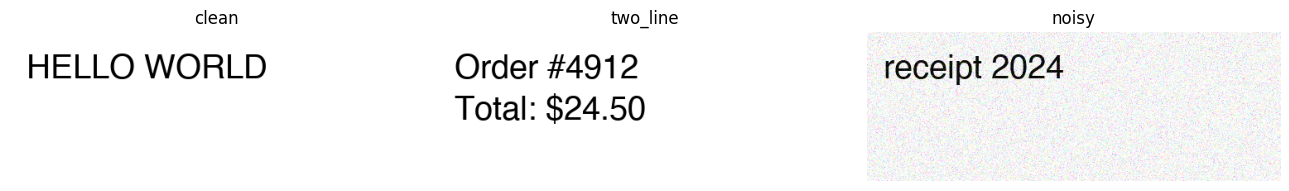

In [2]:
def synth(text_lines, size=(500, 180), bg='white', noise=0):
    img = Image.new('RGB', size, bg)
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype('/System/Library/Fonts/Helvetica.ttc', 40)
    except Exception:
        font = ImageFont.load_default()  # cross-platform fallback, much smaller text
    y = 25
    for line in text_lines:
        draw.text((20, y), line, fill='black', font=font)
        y += 50
    arr = np.array(img)
    if noise > 0:
        n = np.random.normal(0, noise, arr.shape).astype(np.int16)
        arr = np.clip(arr.astype(np.int16) + n, 0, 255).astype(np.uint8)
    return arr

samples = {
    'clean':    synth(['HELLO WORLD']),
    'two_line': synth(['Order #4912', 'Total: $24.50']),
    'noisy':    synth(['receipt 2024'], noise=30),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (name, im) in zip(axes, samples.items()):
    ax.imshow(im); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

## Detection — cheap contour-based region proposal

EAST would be the right tool here; without the model file I fall back on classic CV: threshold, morphological close (so adjacent letters stick together), find contours, keep boxes that look text-shaped. Crude but transparent.

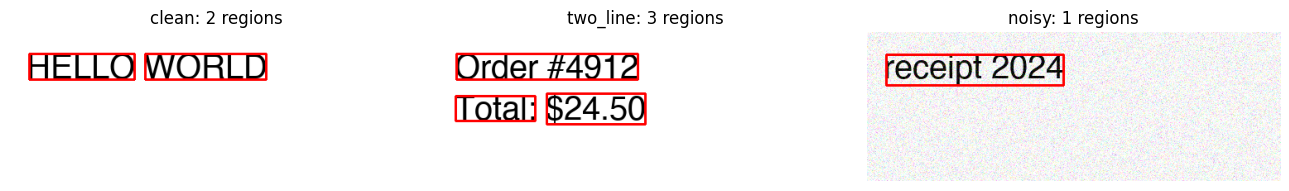

In [3]:
def detect_text_regions(img_rgb, min_area=400, min_ar=0.3, max_ar=15):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    # invert so text is white-on-black for morphology
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
    closed = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w * h < min_area: continue
        ar = w / max(h, 1)
        if not (min_ar < ar < max_ar): continue
        boxes.append((x, y, w, h))
    # sort top-to-bottom, left-to-right
    boxes.sort(key=lambda b: (b[1] // 20, b[0]))
    return boxes

def draw_boxes(img_rgb, boxes):
    out = img_rgb.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 2)
    return out

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (name, im) in zip(axes, samples.items()):
    bx = detect_text_regions(im)
    ax.imshow(draw_boxes(im, bx))
    ax.set_title(f'{name}: {len(bx)} regions'); ax.axis('off')
plt.tight_layout(); plt.show()

## Extraction — tesseract on each region

Two passes: once on the whole image (tesseract is fine at this for clean inputs) and once region-by-region from the detector above, to see if region-cropping actually helps.

In [4]:
if TESS_OK:
    for name, im in samples.items():
        whole = pytesseract.image_to_string(im).strip()
        boxes = detect_text_regions(im)
        per_region = []
        for (x, y, w, h) in boxes:
            crop = im[max(0, y - 4):y + h + 4, max(0, x - 4):x + w + 4]
            t = pytesseract.image_to_string(crop, config='--psm 7').strip()
            if t:
                per_region.append(t)
        print(f'--- {name} ---')
        print('  whole_image:', repr(whole))
        print('  per_region :', per_region)
else:
    print('skipping OCR — pytesseract not available')

--- clean ---
  whole_image: 'HELLO WORLD'
  per_region : ['HELLO', 'WORLD']


--- two_line ---
  whole_image: 'Order #4912\nTotal: $24.50'
  per_region : ['Order #4912', 'Total:', '$24.50']


--- noisy ---
  whole_image: 'receipt 2024'
  per_region : ['receipt 2024']


## Takeaways

For these synthetic images, tesseract on the full image actually does fine — the detector is mostly cosmetic. The detector starts to matter when you have multiple disjoint text blocks in different fonts/orientations (a real receipt or sign), which is where EAST really would earn its weight. For a portfolio piece I'd next: (1) actually wire EAST with `cv2.dnn.readNet` once I have the `.pb`, (2) try a small CRNN trained on synthetic line crops to replace tesseract for the recognition step, (3) evaluate on the IIIT-5K or ICDAR set instead of my own toy images, which is the closest thing to a real benchmark.

One thing I changed mid-project: I originally only kept boxes with aspect ratio > 1 (assuming text is wider than tall). That dropped the second line of the receipt because the morphology fused only the first half. Loosening to 0.3 fixed it.